## 04\_rouen\_objectifs\_1\_2

# 04 · Objectifs 1 et 2 : accessibilité et population desservie

1. **Objectif 1** : nombre d'options de transport accessibles à 5 minutes à pied depuis chaque carreau, en 4 classes. Par commune, nombre moyen d'options par habitant et part d'habitants sans option à 5 minutes.
2. **Objectif 2** : nombre d'habitants desservis par chaque arrêt ou station.
3. **Confidentialité** : les carreaux dont les valeurs sont estimées par l'INSEE (moins de 11 ménages) sont agrégés en mailles de 1 km et ne sont jamais représentés isolément.

Les communes au plus faible accès sont désignées comme zones à **potentiel de développement**.

**Entrées :** `carreaux_rouen`, `options_rouen` (notebook 02), `zones_5min` (notebook 03).

**Sorties :** tables `carreaux_rouen` et `options_rouen` (complétées), `carte_acces` (carte publiable), `acces_communes` ; cartes PNG et HTML dans `Files/traite/cartes`.

In [ ]:
# 1. Dépendances
%pip install -q geopandas pyogrio py7zr folium

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# 2. Outils communs
import os, re, glob, shutil, tempfile, zipfile, warnings
import numpy as np
import pandas as pd
from pyproj import Transformer
warnings.filterwarnings("ignore")

BASE = "/lakehouse/default/Files"
if not os.path.isdir(BASE):
    raise RuntimeError("Lakehouse par défaut non attaché : attacher le Lakehouse mobilite au notebook.")
BRUT = os.path.join(BASE, "brut")
TRAITE = os.path.join(BASE, "traite")
CARTES = os.path.join(TRAITE, "cartes")
os.makedirs(CARTES, exist_ok=True)

# Conversions entre systèmes de coordonnées : 3035 = grille INSEE, 2154 = Lambert-93 (mètres), 4326 = GPS
T_3035_2154 = Transformer.from_crs(3035, 2154, always_xy=True)
T_3035_4326 = Transformer.from_crs(3035, 4326, always_xy=True)
T_4326_3035 = Transformer.from_crs(4326, 3035, always_xy=True)
T_4326_2154 = Transformer.from_crs(4326, 2154, always_xy=True)

def _copier_csv(df, chemin):
    """Écrit le CSV en local, puis le copie dans le Lakehouse. Écrire directement dans OneLake échoue parfois
    quand le fichier existe déjà (« Unable to rename file »)."""
    fd, tmp = tempfile.mkstemp(suffix=".csv")
    os.close(fd)
    try:
        df.to_csv(tmp, index=False)
        if os.path.exists(chemin):
            os.remove(chemin)
        shutil.copyfile(tmp, chemin)
    finally:
        os.remove(tmp)

def _adresse_table(nom):
    """Adresse OneLake de la table dans le Lakehouse attaché, dans le schéma dbo s'il existe."""
    import notebookutils
    ctx = notebookutils.runtime.context
    espace = ctx.get("defaultLakehouseWorkspaceId") or ctx.get("currentWorkspaceId")
    lakehouse = ctx.get("defaultLakehouseId")
    if not (espace and lakehouse):
        raise RuntimeError("Lakehouse par défaut introuvable : attacher le Lakehouse mobilite au notebook")
    schema = "/dbo" if os.path.isdir("/lakehouse/default/Tables/dbo") else ""
    return f"abfss://{espace}@onelake.dfs.fabric.microsoft.com/{lakehouse}/Tables{schema}/{nom}"

def _ecrire_table(df, nom):
    """Table Delta lue par Power BI. Noyau Spark : saveAsTable. Noyau Python : bibliothèque deltalake."""
    try:
        spark  # n'existe que dans le noyau Spark
    except NameError:
        import pyarrow as pa
        import notebookutils
        from deltalake import write_deltalake
        donnees = pa.Table.from_pandas(df, preserve_index=False)
        options = {"bearer_token": notebookutils.credentials.getToken("storage"), "use_fabric_endpoint": "true"}
        try:
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", schema_mode="overwrite",
                            storage_options=options)
        except TypeError:   # anciennes versions de deltalake
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", overwrite_schema=True,
                            storage_options=options)
        return
    spark.createDataFrame(df).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(nom)

def enregistrer(df, nom):
    """Enregistre un tableau en CSV dans Files/traite (relu par les autres notebooks)
    et en table du Lakehouse (lue par Power BI), avec le noyau Python comme avec le noyau Spark."""
    df = df.reset_index(drop=True).copy()
    _copier_csv(df, os.path.join(TRAITE, nom + ".csv"))
    for c in df.columns:
        if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c])):
            df[c] = df[c].map(lambda v: None if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    try:
        _ecrire_table(df, nom)
        print(f"   table {nom} : {len(df)} lignes (copie dans Files/traite/{nom}.csv)")
    except Exception as e:
        print(f"   {nom}.csv : {len(df)} lignes. ATTENTION, table non créée pour Power BI : {e}")

def nb(n):
    """Écrit un nombre avec des espaces entre les milliers : 12 345."""
    return f"{n:,.0f}".replace(",", " ")

def lire(nom):
    """Relit un tableau enregistré par un autre notebook."""
    chemin = os.path.join(TRAITE, nom + ".csv")
    if not os.path.exists(chemin):
        raise FileNotFoundError(f"{nom}.csv introuvable dans Files/traite : exécuter d'abord le notebook qui le produit.")
    return pd.read_csv(chemin, dtype={"idcar": str, "commune": str, "idcar_1km": str, "candidat": str})

COLONNES_FILOSOFI = ["idcar_200m", "idcar_1km", "i_est_200", "lcog_geo", "ind", "men", "men_pauv", "men_1ind",
                     "men_5ind", "men_prop", "men_fmp", "ind_snv", "men_surf", "men_coll", "men_mais", "log_av45",
                     "log_45_70", "log_70_90", "log_ap90", "log_inc", "log_soc", "ind_0_3", "ind_4_5", "ind_6_10",
                     "ind_11_17", "ind_18_24", "ind_25_39", "ind_40_54", "ind_55_64", "ind_65_79", "ind_80p", "ind_inc"]
TEXTE_FILOSOFI = ["idcar_200m", "idcar_1km", "lcog_geo"]

def charger_filosofi():
    """Carreaux de 200 m de métropole (CSV ou GeoPackage), avec leur centre en coordonnées 3035."""
    csvs = sorted(glob.glob(os.path.join(BRUT, "filosofi", "**", "*.csv"), recursive=True),
                  key=os.path.getsize, reverse=True)
    csvs = [c for c in csvs if "met" in os.path.basename(c).lower()] or csvs
    if csvs:
        source = csvs[0]
        with open(source, encoding="utf-8", errors="replace") as f:
            entete = f.readline()
        sep = ";" if entete.count(";") > entete.count(",") else ","
        noms = [c.strip().strip('"') for c in entete.strip().split(sep)]
        utiles = [c for c in noms if c.lower() in COLONNES_FILOSOFI]
        df = pd.read_csv(source, sep=sep, usecols=utiles,
                         dtype={c: str for c in utiles if c.lower() in TEXTE_FILOSOFI})
    else:
        gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
                 if "carreaux" in os.path.basename(g).lower() and "met" in os.path.basename(g).lower()]
        if not gpkgs:
            raise FileNotFoundError("Carreaux Filosofi introuvables dans Files/brut/filosofi (notebook 01).")
        import pyogrio
        source = gpkgs[0]
        df = pyogrio.read_dataframe(source, read_geometry=False)
    df.columns = [c.lower() for c in df.columns]
    df = df[[c for c in COLONNES_FILOSOFI if c in df.columns]].copy()
    for c in df.columns:
        if c not in TEXTE_FILOSOFI and not pd.api.types.is_numeric_dtype(df[c]):   # décimales avec une virgule
            df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    nombres = [c for c in df.columns if c not in TEXTE_FILOSOFI]
    df[nombres] = df[nombres].fillna(0)
    # L'identifiant INSPIRE donne le coin sud-ouest du carreau en mètres : CRS3035RES200mN<nord>E<est>
    ne = df["idcar_200m"].astype(str).str.extract(r"CRS3035RES200mN(\d+)E(\d+)").astype(float)
    df["x3035"], df["y3035"] = ne[1] + 100, ne[0] + 100
    df = df.dropna(subset=["x3035", "y3035"])
    df["ix"] = ((df["x3035"] - 100) // 200).astype("int64")
    df["iy"] = ((df["y3035"] - 100) // 200).astype("int64")
    df["commune"] = df["lcog_geo"].astype(str).str[:5]
    df = df.rename(columns={"idcar_200m": "idcar"}).reset_index(drop=True)
    print(f"Filosofi : {nb(len(df))} carreaux de métropole lus ({os.path.basename(source)})")
    return df

def trouver_admin_express():
    """GeoPackage ADMIN EXPRESS : déjà extrait, ou extrait de l'archive .7z déposée dans Files/brut."""
    gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
             if "ADE" in os.path.basename(g).upper() or "ADMIN" in os.path.basename(g).upper()]
    if gpkgs:
        return gpkgs[0]
    archives = [a for a in glob.glob(os.path.join(BRUT, "**", "*.7z"), recursive=True) if "ADMIN" in a.upper()]
    if not archives:
        raise FileNotFoundError("Contours introuvables : fichiers IGN du notebook 01 ou archive ADMIN-EXPRESS (.7z) attendus dans Files/brut.")
    import py7zr
    with py7zr.SevenZipFile(sorted(archives)[-1], "r") as z:
        z.extractall(os.path.join(BRUT, "ign"))
    return trouver_admin_express()

def charger_territoire(court, mot):
    """Contour de l'intercommunalité (Lambert-93) et ses communes."""
    import geopandas as gpd
    f_epci = os.path.join(BRUT, f"epci_{court}.geojson")
    f_communes = os.path.join(BRUT, f"communes_{court}.geojson")
    if os.path.exists(f_epci) and os.path.exists(f_communes):
        epci = gpd.read_file(f_epci).to_crs(2154)
        communes = gpd.read_file(f_communes).to_crs(2154)
    else:
        gpkg = trouver_admin_express()
        epci = gpd.read_file(gpkg, layer="epci")
        epci = epci[epci["nom_officiel"].str.contains(mot, case=False, na=False)].to_crs(2154)
        siren = str(epci.iloc[0]["code_siren"])
        communes = gpd.read_file(gpkg, layer="commune")
        communes = communes[communes["codes_siren_des_epci"].astype(str).str.contains(siren, na=False)].to_crs(2154)
    contour = epci.geometry.iloc[0]
    communes = communes[["code_insee", "nom_officiel", "geometry"]].rename(
        columns={"code_insee": "commune", "nom_officiel": "commune_nom"})
    print(f"{epci.iloc[0]['nom_officiel']} : {len(communes)} communes, {contour.area / 1e6:.0f} km²")
    return contour, communes

def dans_contour(contour, x, y):
    """Vrai pour les points (Lambert-93) situés dans le contour."""
    import shapely
    xmin, ymin, xmax, ymax = contour.bounds
    resultat = np.zeros(len(x), dtype=bool)
    cadre = (x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax)
    shapely.prepare(contour)
    resultat[cadre] = shapely.contains_xy(contour, x[cadre], y[cadre])
    return resultat

In [ ]:
# 3. Données du notebook 02 et zones du notebook 03
import geopandas as gpd
carreaux = lire("carreaux_rouen")
options = lire("options_rouen")
zones = lire("zones_5min").merge(options[["option_id", "type"]], on="option_id")

# Commune de chaque carreau d'après son centre et les contours IGN 2026. Cela corrige les carreaux à cheval
# sur deux communes et les codes Filosofi (géographie 2021) qui auraient changé depuis.
_, communes_ign = charger_territoire("rouen", "Rouen")
points = gpd.GeoDataFrame(carreaux[["idcar"]], geometry=gpd.points_from_xy(carreaux["x"], carreaux["y"]), crs=2154)
rattache = gpd.sjoin(points, communes_ign[["commune", "commune_nom", "geometry"]], how="left", predicate="within")
rattache = rattache[~rattache.index.duplicated()].reindex(points.index)
change = int((rattache["commune"].notna() & (rattache["commune"].astype(str).values != carreaux["commune"].astype(str).values)).sum())
carreaux["commune"] = rattache["commune"].fillna(carreaux["commune"]).values
carreaux["commune_nom"] = rattache["commune_nom"].fillna(carreaux["commune_nom"]).values
print(f"Communes : {change} carreaux rattachés à une autre commune d'après leur centre")
CLASSES = ["0 option", "1 à 2", "3 à 5", "6 et plus"]
def classe(n):
    return CLASSES[0] if n == 0 else CLASSES[1] if n <= 2 else CLASSES[2] if n <= 5 else CLASSES[3]

Métropole Rouen Normandie : 71 communes, 664 km²
Communes : 41 carreaux rattachés à une autre commune d'après leur centre


In [ ]:
# 4. Objectif 1 : options accessibles depuis chaque carreau, et par commune
par_carreau = zones.groupby("idcar")["option_id"].nunique().rename("nb_options")
par_type = zones.pivot_table(index="idcar", columns="type", values="option_id", aggfunc="nunique", fill_value=0)
par_type.columns = ["nb_" + re.sub(r"[^a-z]", "_", c.lower().replace("é", "e").replace("è", "e")) for c in par_type.columns]
carreaux = carreaux.drop(columns=[c for c in carreaux.columns if c.startswith("nb_") or c == "classe_acces"])
carreaux = carreaux.merge(par_carreau, left_on="idcar", right_index=True, how="left").merge(par_type, left_on="idcar", right_index=True, how="left")
colonnes_nb = ["nb_options"] + list(par_type.columns)
carreaux[colonnes_nb] = carreaux[colonnes_nb].fillna(0).astype(int)
carreaux["classe_acces"] = carreaux["nb_options"].apply(classe)

pop = carreaux["population"].sum()
sans = carreaux.loc[carreaux["nb_options"] == 0, "population"].sum()
print(f"Habitants avec au moins une option à 5 minutes : {100 * (1 - sans / pop):.0f} %")
print(f"Nombre moyen d'options accessibles par habitant : {np.average(carreaux['nb_options'], weights=carreaux['population']):.1f}")
print(carreaux.groupby("classe_acces")["population"].sum().reindex(CLASSES).fillna(0).apply(lambda v: f"{nb(v)} habitants").to_string())

communes_ind = carreaux.groupby(["commune", "commune_nom"]).apply(lambda g: pd.Series({
    "population": g["population"].sum(),
    "options_par_habitant": np.average(g["nb_options"], weights=g["population"]) if g["population"].sum() > 0 else 0,
    "part_sans_option": g.loc[g["nb_options"] == 0, "population"].sum() / max(g["population"].sum(), 1),
})).reset_index().sort_values("options_par_habitant")
communes_ind[["options_par_habitant", "part_sans_option"]] = communes_ind[["options_par_habitant", "part_sans_option"]].round(3)
print("\nLes 5 communes où l'on a le moins d'options à 5 minutes (potentiel de développement) :")
print(communes_ind.head(5)[["commune_nom", "population", "options_par_habitant", "part_sans_option"]].to_string(index=False))

Habitants avec au moins une option à 5 minutes : 78 %
Nombre moyen d'options accessibles par habitant : 1.9
classe_acces
0 option     101 844 habitants
1 à 2        214 864 habitants
3 à 5        118 048 habitants
6 et plus     18 696 habitants

Les 5 communes où l'on a le moins d'options à 5 minutes (potentiel de développement) :
           commune_nom  population  options_par_habitant  part_sans_option
    Berville-sur-Seine       525.0                 0.190             0.810
 Anneville-Ambourville      1156.5                 0.290             0.710
Saint-Aubin-Celloville      1141.5                 0.297             0.703
Quévreville-la-Poterie      1048.5                 0.385             0.632
                  Gouy       902.5                 0.408             0.592


In [ ]:
# 5. Objectif 2 : habitants desservis par chaque option
pop_car = carreaux.set_index("idcar")["population"]
options = options.drop(columns=[c for c in ["pop_desservie"] if c in options.columns])
options = options.merge(zones.assign(p=zones["idcar"].map(pop_car)).groupby("option_id")["p"].sum().rename("pop_desservie"),
                        left_on="option_id", right_index=True, how="left")
options["pop_desservie"] = options["pop_desservie"].fillna(0).round(0)
resume = options.groupby("type").agg(nombre=("option_id", "size"), habitants_par_option=("pop_desservie", "median"))
deja = {t: carreaux.loc[carreaux["idcar"].isin(zones.loc[zones["type"] == t, "idcar"]), "population"].sum() for t in resume.index}
resume["habitants_desservis_au_total"] = pd.Series(deja).round(0)
print(resume.sort_values("habitants_desservis_au_total", ascending=False).to_string())

                       nombre  habitants_par_option  habitants_desservis_au_total
type                                                                             
Bus                      1053                 330.0                      296720.0
Vélo en libre-service     126                1434.0                      102780.0
TEOR                       70                1057.5                       63232.0
Métro                      31                1552.0                       45017.0
Gare TER                    8                 342.0                        3700.0


In [ ]:
# 6. Table de carte respectueuse de la vie privée : carreaux estimés regroupés par maille de 1 km
fiables = carreaux[carreaux["i_est_200"] == 0].assign(niveau="carreau de 200 m")
estimes = carreaux[carreaux["i_est_200"] == 1]
mailles = estimes.groupby("idcar_1km").apply(lambda g: pd.Series({
    "population": g["population"].sum(),
    "nb_options": int(round(np.average(g["nb_options"], weights=g["population"]))) if g["population"].sum() > 0 else 0,
    "commune_nom": g["commune_nom"].mode().iat[0]})).reset_index()
ne = mailles["idcar_1km"].astype(str).str.extract(r"N(\d+)E(\d+)").astype(float)
mailles["lon"], mailles["lat"] = T_3035_4326.transform(ne[1].values + 500, ne[0].values + 500)
mailles["classe_acces"] = mailles["nb_options"].apply(classe)
mailles["niveau"] = "maille de 1 km (valeurs estimées regroupées)"
mailles = mailles.rename(columns={"idcar_1km": "idcar"})
carte = pd.concat([fiables[["idcar", "commune_nom", "lat", "lon", "population", "nb_options", "classe_acces", "niveau"]],
                   mailles[["idcar", "commune_nom", "lat", "lon", "population", "nb_options", "classe_acces", "niveau"]]],
                  ignore_index=True)
carte["ordre_classe"] = carte["classe_acces"].map({c: i for i, c in enumerate(CLASSES)})
print(f"Carte : {len(fiables)} carreaux affichés tels quels, {len(estimes)} carreaux estimés regroupés en {len(mailles)} mailles de 1 km")

print("Enregistrement :")
enregistrer(carreaux, "carreaux_rouen")
enregistrer(carte, "carte_acces")
enregistrer(communes_ind, "acces_communes")
enregistrer(options, "options_rouen")

Carte : 3065 carreaux affichés tels quels, 2662 carreaux estimés regroupés en 568 mailles de 1 km
Enregistrement :
   table carreaux_rouen : 5727 lignes (copie dans Files/traite/carreaux_rouen.csv)
   table carte_acces : 3633 lignes (copie dans Files/traite/carte_acces.csv)
   table acces_communes : 71 lignes (copie dans Files/traite/acces_communes.csv)
   table options_rouen : 1288 lignes (copie dans Files/traite/options_rouen.csv)


Métropole Rouen Normandie : 71 communes, 664 km²


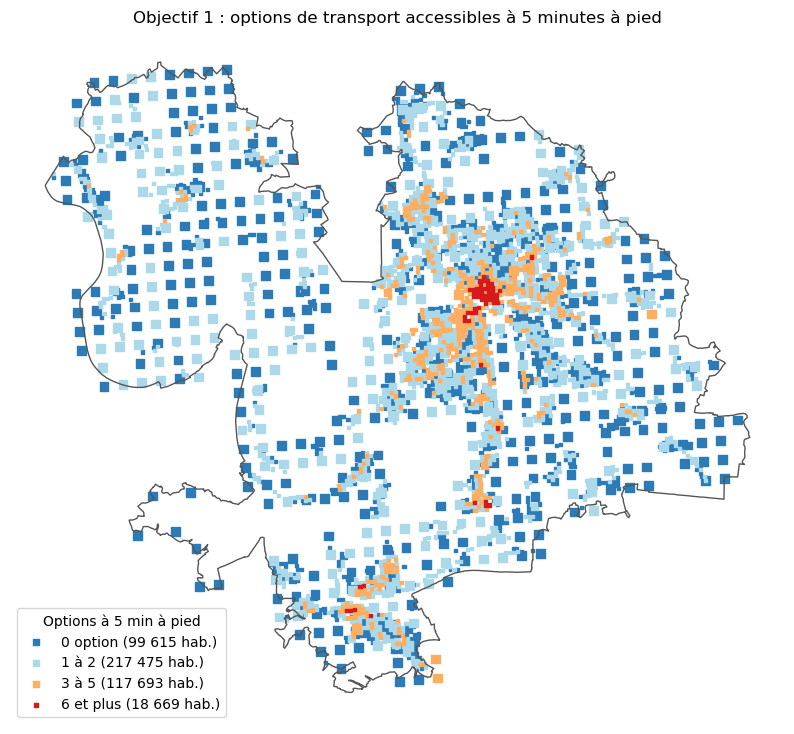

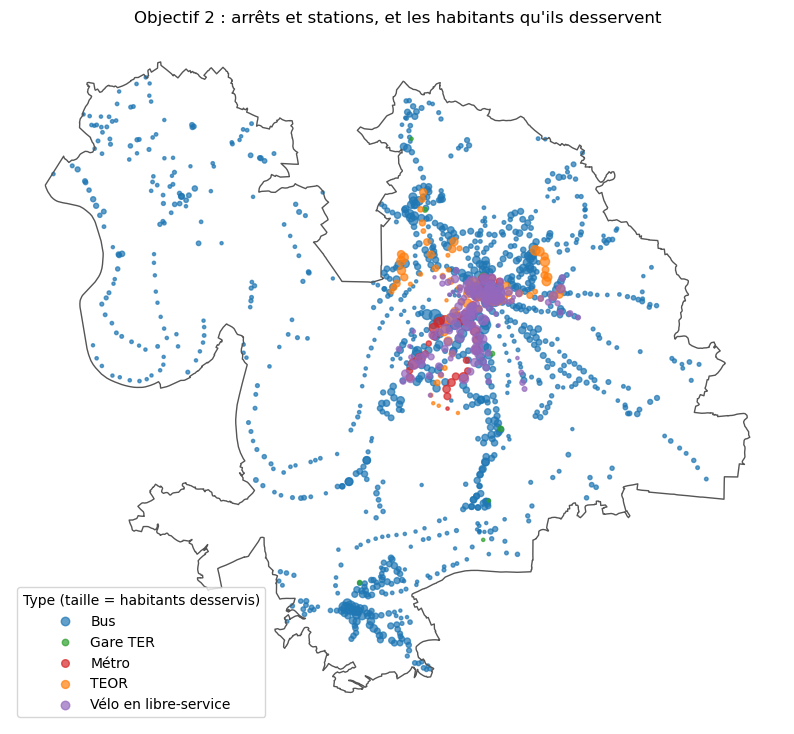

In [ ]:
# 7. Cartes statiques (PNG)
import matplotlib.pyplot as plt
import geopandas as gpd
contour, _ = charger_territoire("rouen", "Rouen")
T_4326_2154_ = Transformer.from_crs(4326, 2154, always_xy=True)
carte["x"], carte["y"] = T_4326_2154_.transform(carte["lon"].values, carte["lat"].values)
couleurs_classes = ["#2c7bb6", "#abd9e9", "#fdae61", "#d7191c"]

fig, ax = plt.subplots(figsize=(10, 10))
gpd.GeoSeries([contour], crs=2154).boundary.plot(ax=ax, color="#555555", linewidth=1)
for c, coul in zip(CLASSES, couleurs_classes):
    g = carte[carte["classe_acces"] == c]
    ax.scatter(g["x"], g["y"], s=np.where(g["niveau"].str.startswith("maille"), 40, 5), color=coul, marker="s",
               label=f"{c} ({nb(g['population'].sum())} hab.)")
ax.legend(title="Options à 5 min à pied", loc="lower left")
ax.set_title("Objectif 1 : options de transport accessibles à 5 minutes à pied")
ax.set_axis_off()
plt.savefig(os.path.join(CARTES, "objectif1_acces.png"), dpi=130, bbox_inches="tight")
plt.show()

couleurs_types = {"Métro": "#d62728", "TEOR": "#ff7f0e", "Bus": "#1f77b4", "Gare TER": "#2ca02c", "Vélo en libre-service": "#9467bd"}
fig, ax = plt.subplots(figsize=(10, 10))
gpd.GeoSeries([contour], crs=2154).boundary.plot(ax=ax, color="#555555", linewidth=1)
for t, g in options.groupby("type"):
    ax.scatter(g["x"], g["y"], s=5 + g["pop_desservie"] / 60, color=couleurs_types.get(t, "black"), alpha=0.7, label=t)
ax.legend(title="Type (taille = habitants desservis)", loc="lower left")
ax.set_title("Objectif 2 : arrêts et stations, et les habitants qu'ils desservent")
ax.set_axis_off()
plt.savefig(os.path.join(CARTES, "objectif2_desserte.png"), dpi=130, bbox_inches="tight")
plt.show()

In [ ]:
# 8. Cartes interactives (HTML)
import folium
centre = [carte["lat"].mean(), carte["lon"].mean()]
m1 = folium.Map(location=centre, zoom_start=11, tiles="OpenStreetMap")
for _, r in carte.iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius=3 if r["niveau"].startswith("carreau") else 7, weight=0, fill=True,
                        fill_opacity=0.75, fill_color=couleurs_classes[int(r["ordre_classe"])],
                        tooltip=f"{r['commune_nom']} · {int(r['population'])} hab. · {int(r['nb_options'])} options").add_to(m1)
m1.save(os.path.join(CARTES, "objectif1_acces.html"))
m2 = folium.Map(location=centre, zoom_start=11, tiles="OpenStreetMap")
for _, r in options.iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius=2 + (r["pop_desservie"] ** 0.5) / 8, weight=0, fill=True, fill_opacity=0.7,
                        fill_color=couleurs_types.get(r["type"], "black"),
                        tooltip=f"{r['type']} · {r['nom']} · {int(r['pop_desservie'])} habitants").add_to(m2)
m2.save(os.path.join(CARTES, "objectif2_desserte.html"))
print("Cartes interactives enregistrées dans Files/traite/cartes (objectif1_acces.html, objectif2_desserte.html)")
m1

Cartes interactives enregistrées dans Files/traite/cartes (objectif1_acces.html, objectif2_desserte.html)


Carte interactive enregistrée à part dans le dépôt : demo/carte_acces_5min.html (à télécharger, puis à ouvrir dans un navigateur).
